# Kernel SVM : CV vs Held-Out


## 0. Mount Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Paths

In [ ]:
CSV_PATH     = "/content/drive/MyDrive/Phishing_Email/final_dataset/nlp_final_features_reduced.csv"
NLP_DIR      = "/content/drive/MyDrive/Phishing_Email/nlp_features"
RESULTS_DIR  = "/content/drive/MyDrive/Phishing_Email/results/cv_audit"

TARGET_ROWS  = 41_000
TEST_SIZE    = 0.2
RANDOM_STATE = 42
N_SPLITS     = 5

import os
os.makedirs(RESULTS_DIR, exist_ok=True)
print("Paths set.")

Paths set.


## 2. Load & audit the raw CSV

In [ ]:
import pandas as pd
import numpy as np

df_raw = pd.read_csv(CSV_PATH)
print(f"Rows loaded from CSV          : {len(df_raw):,}")
print(f"Columns                       : {list(df_raw.columns)}")
print(f"\nClass distribution (raw):")
print(df_raw["label"].value_counts())
print(f"\nNull counts:")
print(df_raw.isnull().sum())

Rows loaded from CSV          : 41,000
Columns                       : ['label', 'clean_text', 'word_count', 'avg_word_length', 'uppercase_ratio', 'url_like_count', 'text_entropy', 'action_density', 'has_attachment', 'repeated_char_patterns', 'writing_error_total']

Class distribution (raw):
label
0    23878
1    17122
Name: count, dtype: int64

Null counts:
label                     0
clean_text                0
word_count                0
avg_word_length           0
uppercase_ratio           0
url_like_count            0
text_entropy              0
action_density            0
has_attachment            0
repeated_char_patterns    0
writing_error_total       0
dtype: int64


## 3. Reproduce the original 41k preprocessing exactly

In [ ]:
df = df_raw.dropna(subset=["clean_text", "label"]).reset_index(drop=True)
print(f"After null drop               : {len(df):,}")

df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)
print(f"After exact-duplicate removal : {len(df):,}")

if len(df) > TARGET_ROWS:
    df = df.iloc[:TARGET_ROWS].reset_index(drop=True)
    print(f"After cap at {TARGET_ROWS:,}         : {len(df):,}  ← matches original training")
else:
    print(f"Rows after de-dup ({len(df):,}) < {TARGET_ROWS:,} cap - no truncation needed")

print(f"\nClass distribution after preprocessing:")
print(df["label"].value_counts())
print(f"\nClass balance: {df['label'].mean():.4f} phishing rate")

After null drop               : 41,000
After exact-duplicate removal : 41,000
Rows after de-dup (41,000) < 41,000 cap - no truncation needed

Class distribution after preprocessing:
label
0    23878
1    17122
Name: count, dtype: int64

Class balance: 0.4176 phishing rate


## 4. Build features - same as original training cells

In [ ]:
import joblib
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from scipy.sparse import hstack as sp_hstack, csr_matrix

numerical_features = [
    "word_count", "avg_word_length", "uppercase_ratio", "url_like_count",
    "text_entropy", "action_density", "has_attachment",
    "repeated_char_patterns", "writing_error_total"
]

num_cols = [c for c in numerical_features if c in df.columns]
print(f"Numerical features available  : {num_cols}")

X_text = df["clean_text"].fillna("").values
X_num  = df[num_cols].fillna(0).values
y      = df["label"].values

X_train_text, X_test_text, X_train_num, X_test_num, y_train, y_test = train_test_split(
    X_text, X_num, y,
    test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

print(f"\nTrain size: {len(y_train):,}  |  Test size: {len(y_test):,}")

tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_tfidf = tfidf.fit_transform(X_train_text)
X_test_tfidf  = tfidf.transform(X_test_text)

scaler = StandardScaler(with_mean=False)
X_train_num_sc = csr_matrix(scaler.fit_transform(X_train_num))
X_test_num_sc  = csr_matrix(scaler.transform(X_test_num))

X_train_final = sp_hstack([X_train_tfidf, X_train_num_sc])
X_test_final  = sp_hstack([X_test_tfidf,  X_test_num_sc])

print(f"Feature matrix shape (train)  : {X_train_final.shape}")
print(f"Feature matrix shape (test)   : {X_test_final.shape}")

Numerical features available  : ['word_count', 'avg_word_length', 'uppercase_ratio', 'url_like_count', 'text_entropy', 'action_density', 'has_attachment', 'repeated_char_patterns', 'writing_error_total']

Train size: 32,800  |  Test size: 8,200
Feature matrix shape (train)  : (32800, 5009)
Feature matrix shape (test)   : (8200, 5009)


## 5. Held-out Kernel SVM

In [ ]:
import time
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, f1_score,
                             precision_score, recall_score, roc_auc_score,
                             classification_report)

print("Training Kernel SVM on held-out train split...")
t0 = time.time()

svm_heldout = SVC(
    C=1.0, kernel="rbf", gamma="scale",
    class_weight="balanced", probability=True, random_state=RANDOM_STATE
)
svm_heldout.fit(X_train_final, y_train)
print(f"  Training time: {time.time()-t0:.1f}s")

y_pred_ho  = svm_heldout.predict(X_test_final)
y_prob_ho  = svm_heldout.predict_proba(X_test_final)[:, 1]

acc_ho  = accuracy_score(y_test, y_pred_ho)
f1_ho   = f1_score(y_test, y_pred_ho, zero_division=0)
prec_ho = precision_score(y_test, y_pred_ho, zero_division=0)
rec_ho  = recall_score(y_test, y_pred_ho, zero_division=0)
auc_ho  = roc_auc_score(y_test, y_prob_ho)

print(f"\n{'='*55}")
print(f"  HELD-OUT TEST RESULT  (41k-capped, de-duped population)")
print(f"{'='*55}")
print(classification_report(y_test, y_pred_ho,
      target_names=["Legitimate", "Phishing"]))
print(f"  Accuracy  : {acc_ho:.4f}  ({acc_ho*100:.2f}%)")
print(f"  F1        : {f1_ho:.4f}")
print(f"  Precision : {prec_ho:.4f}")
print(f"  Recall    : {rec_ho:.4f}")
print(f"  ROC-AUC   : {auc_ho:.4f}")

Training Kernel SVM on held-out train split...
  Training time: 1527.1s

  HELD-OUT TEST RESULT  (41k-capped, de-duped population)
              precision    recall  f1-score   support

  Legitimate       0.96      0.94      0.95      4776
    Phishing       0.92      0.94      0.93      3424

    accuracy                           0.94      8200
   macro avg       0.94      0.94      0.94      8200
weighted avg       0.94      0.94      0.94      8200

  Accuracy  : 0.9401  (94.01%)
  F1        : 0.9292
  Precision : 0.9179
  Recall    : 0.9407
  ROC-AUC   : 0.9816


## 6. 5-Fold CV - same population

In [ ]:
from sklearn.model_selection import StratifiedKFold
from copy import deepcopy

CV = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

print(f"Running {N_SPLITS}-fold CV on SAME {len(y):,}-row population...")
print("(TF-IDF and Scaler fitted within each fold)\n")

fold_acc, fold_f1, fold_prec, fold_rec, fold_auc = [], [], [], [], []

for fold_idx, (tr_idx, te_idx) in enumerate(CV.split(X_text, y)):
    t0 = time.time()

    tfidf_fold = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
    X_tr_tfidf = tfidf_fold.fit_transform(X_text[tr_idx])
    X_te_tfidf = tfidf_fold.transform(X_text[te_idx])

    scaler_fold = StandardScaler(with_mean=False)
    X_tr_num_sc = csr_matrix(scaler_fold.fit_transform(X_num[tr_idx]))
    X_te_num_sc = csr_matrix(scaler_fold.transform(X_num[te_idx]))

    X_tr = sp_hstack([X_tr_tfidf, X_tr_num_sc])
    X_te = sp_hstack([X_te_tfidf, X_te_num_sc])

    est = SVC(
        C=1.0, kernel="rbf", gamma="scale",
        class_weight="balanced", probability=True, random_state=RANDOM_STATE
    )
    est.fit(X_tr, y[tr_idx])

    y_pred = est.predict(X_te)
    y_prob = est.predict_proba(X_te)[:, 1]

    fold_acc.append(accuracy_score(y[te_idx], y_pred))
    fold_f1.append(f1_score(y[te_idx], y_pred, zero_division=0))
    fold_prec.append(precision_score(y[te_idx], y_pred, zero_division=0))
    fold_rec.append(recall_score(y[te_idx], y_pred, zero_division=0))
    fold_auc.append(roc_auc_score(y[te_idx], y_prob))

    print(f"  Fold {fold_idx+1}: acc={fold_acc[-1]:.4f}  f1={fold_f1[-1]:.4f}"
          f"  auc={fold_auc[-1]:.4f}  ({time.time()-t0:.1f}s)")

acc_cv  = np.mean(fold_acc);  acc_cv_std  = np.std(fold_acc)
f1_cv   = np.mean(fold_f1);   f1_cv_std   = np.std(fold_f1)
prec_cv = np.mean(fold_prec); prec_cv_std = np.std(fold_prec)
rec_cv  = np.mean(fold_rec);  rec_cv_std  = np.std(fold_rec)
auc_cv  = np.mean(fold_auc);  auc_cv_std  = np.std(fold_auc)

print(f"\n{'='*55}")
print(f"  CV RESULT  (same 41k-capped population, in-fold TF-IDF)")
print(f"{'='*55}")
print(f"  Accuracy  : {acc_cv:.4f} ± {acc_cv_std:.4f}  ({acc_cv*100:.2f}%)")
print(f"  F1        : {f1_cv:.4f} ± {f1_cv_std:.4f}")
print(f"  Precision : {prec_cv:.4f} ± {prec_cv_std:.4f}")
print(f"  Recall    : {rec_cv:.4f} ± {rec_cv_std:.4f}")
print(f"  ROC-AUC   : {auc_cv:.4f} ± {auc_cv_std:.4f}")

Running 5-fold CV on SAME 41,000-row population...
(TF-IDF and Scaler fitted within each fold)

  Fold 1: acc=0.9398  f1=0.9291  auc=0.9797  (1723.4s)
  Fold 2: acc=0.9449  f1=0.9345  auc=0.9804  (1684.4s)
  Fold 3: acc=0.9390  f1=0.9278  auc=0.9811  (1610.5s)
  Fold 4: acc=0.9379  f1=0.9265  auc=0.9789  (1629.5s)
  Fold 5: acc=0.9421  f1=0.9311  auc=0.9801  (1591.1s)

  CV RESULT  (same 41k-capped population, in-fold TF-IDF)
  Accuracy  : 0.9407 ± 0.0025  (94.07%)
  F1        : 0.9298 ± 0.0028
  Precision : 0.9198 ± 0.0050
  Recall    : 0.9401 ± 0.0031
  ROC-AUC   : 0.9800 ± 0.0007


## 7. Gap analysis & verdict

In [ ]:
gap_acc = acc_ho - acc_cv
gap_f1  = f1_ho  - f1_cv

se_cv   = acc_cv_std / np.sqrt(N_SPLITS)
sigma   = abs(gap_acc) / se_cv if se_cv > 0 else float("inf")

print("=" * 60)
print("  GAP ANALYSIS - Kernel SVM")
print("=" * 60)
print(f"  Held-out accuracy : {acc_ho:.4f}  ({acc_ho*100:.2f}%)")
print(f"  CV accuracy       : {acc_cv:.4f} ± {acc_cv_std:.4f}  ({acc_cv*100:.2f}%)")
print(f"  Gap               : {gap_acc:+.4f}  ({gap_acc*100:+.2f} pp)")
print(f"  σ of gap          : {sigma:.1f}σ")
print()

THRESHOLD_PP  = 0.005
THRESHOLD_SIG = 3.0

if abs(gap_acc) < THRESHOLD_PP:
    verdict = "RESOLVED - gap is within natural variance (<0.5pp). Population mismatch was the cause."
elif sigma < THRESHOLD_SIG:
    verdict = f"SUBSTANTIALLY REDUCED - gap now {gap_acc*100:.2f}pp ({sigma:.1f}σ). Acceptable."
else:
    verdict = (f"GAP PERSISTS - {gap_acc*100:.2f}pp ({sigma:.1f}σ). "
               "Investigate class balance per fold or Platt scaling overhead.")

print(f"  VERDICT: {verdict}")
print()

import pandas as pd, os
result_df = pd.DataFrame([{
    "Metric":          "Accuracy",
    "Held-out":        round(acc_ho, 4),
    "CV mean":         round(acc_cv, 4),
    "CV std":          round(acc_cv_std, 4),
    "Gap (pp)":        round(gap_acc * 100, 3),
    "Sigma":           round(sigma, 1),
}, {
    "Metric":          "F1",
    "Held-out":        round(f1_ho, 4),
    "CV mean":         round(f1_cv, 4),
    "CV std":          round(f1_cv_std, 4),
    "Gap (pp)":        round(gap_f1 * 100, 3),
    "Sigma":           None,
}, {
    "Metric":          "ROC-AUC",
    "Held-out":        round(auc_ho, 4),
    "CV mean":         round(auc_cv, 4),
    "CV std":          round(auc_cv_std, 4),
    "Gap (pp)":        round((auc_ho - auc_cv) * 100, 3),
    "Sigma":           None,
}])

out_csv = os.path.join(RESULTS_DIR, "kernel_svm_cv_audit.csv")
result_df.to_csv(out_csv, index=False)
print(f"  Results saved → {out_csv}")
print()
print(result_df.to_string(index=False))

  GAP ANALYSIS - Kernel SVM
  Held-out accuracy : 0.9401  (94.01%)
  CV accuracy       : 0.9407 ± 0.0025  (94.07%)
  Gap               : -0.0006  (-0.06 pp)
  σ of gap          : 0.6σ

  VERDICT: RESOLVED - gap is within natural variance (<0.5pp). Population mismatch was the cause.

  Results saved → /content/drive/MyDrive/Phishing_Email/results/cv_audit/kernel_svm_cv_audit.csv

  Metric  Held-out  CV mean  CV std  Gap (pp)  Sigma
Accuracy    0.9401   0.9407  0.0025    -0.061    0.6
      F1    0.9292   0.9298  0.0028    -0.064    NaN
 ROC-AUC    0.9816   0.9800  0.0007     0.152    NaN


## 8. Fold-level plot

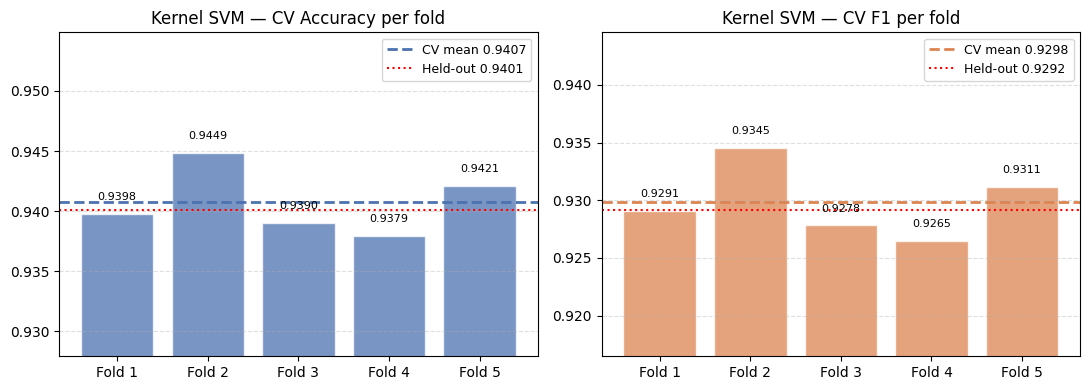

Plot saved → /content/drive/MyDrive/Phishing_Email/results/cv_audit/kernel_svm_cv_audit_plot.png


In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

fold_labels = [f"Fold {i+1}" for i in range(N_SPLITS)]

for ax, vals, mean, label, color in [
    (axes[0], fold_acc, acc_cv, "Accuracy", "#4C72B0"),
    (axes[1], fold_f1,  f1_cv,  "F1",       "#DD8452"),
]:
    ax.bar(fold_labels, vals, color=color, alpha=0.75, edgecolor="white")
    ax.axhline(mean, color=color, lw=2, linestyle="--", label=f"CV mean {mean:.4f}")
    ax.axhline(acc_ho if label == "Accuracy" else f1_ho,
               color="red", lw=1.5, linestyle=":", label=f"Held-out {acc_ho if label=='Accuracy' else f1_ho:.4f}")
    ax.set_title(f"Kernel SVM - CV {label} per fold")
    ax.set_ylim(min(vals) - 0.01, max(vals) + 0.01)
    ax.legend(fontsize=9)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    for i, v in enumerate(vals):
        ax.text(i, v + 0.001, f"{v:.4f}", ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plot_path = os.path.join(RESULTS_DIR, "kernel_svm_cv_audit_plot.png")
plt.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Plot saved → {plot_path}")